# ⏱️ Pocket Clock — combien de temps le QB a-t-il vraiment ?
NFL **2021** sem. 1-8 (Big Data Bowl 2023). Métrique inventée : **Clean Pocket Time (CPT)** = secondes entre le snap et le 1er moment où un pass rusher passe à < 2 yd du QB. Si personne n'arrive avant le lancer/sack, l'action est *censurée* (gardée, traitée par Kaplan-Meier).

In [1]:
import os, sys; os.chdir(os.path.dirname(os.path.abspath('')) if os.path.basename(os.getcwd())=='notebooks' else os.getcwd()); sys.path.insert(0, os.getcwd())
import pandas as pd; from IPython.display import Image, display
from src import load, metrics, analysis as A, validate, viz
# DEBUG=1 dans l'environnement -> 5 matchs seulement

## 1. Chargement (cache parquet) et CPT

In [2]:
t = load.load_all(); load.summary(t)
tab, duels, sk = metrics.build_table(t); metrics.summary(tab, sk)
tab.head()

[load] mode=FULL | matchs=122 | actions plays.csv=8557 | actions trackées (avec snap)=8533 | sautées (sans snap)=24 | lignes tracking=6,327,553


[cpt] radius=2.0 yd | actions=8532 (sautées: 25) | CPT médian=2.60s | censurées=67.9% | CPT=0: 0.4%


,gameId,playId,duration,first_rusherId,cpt,first_entry_speed,censored,cpt_1.5,cpt_2.0,cpt_3.0,...,quarter,n_rushers,n_blockers,qbId,pff_pressure,first_rusher,qb,first_blockerId,first_blocker,first_blocker_pos
0,2021090900,97,3.2,NaN,3.2,NaN,True,3.2,3.2,2.6,...,1,5,5,25511,True,NaN,Tom Brady,NaN,NaN,NaN
1,2021090900,137,2.6,NaN,2.6,NaN,True,2.6,2.6,2.4,...,1,5,5,43424,False,NaN,Dak Prescott,NaN,NaN,NaN
2,2021090900,187,2.0,NaN,2.0,NaN,True,2.0,2.0,2.0,...,1,4,5,43424,False,NaN,Dak Prescott,NaN,NaN,NaN
3,2021090900,282,3.2,NaN,3.2,NaN,True,3.2,3.2,0.0,...,1,5,7,43424,False,NaN,Dak Prescott,NaN,NaN,NaN
4,2021090900,349,2.6,38588.0,2.2,3.98,False,2.6,2.2,1.8,...,1,5,6,43424,True,Lavonte David,Dak Prescott,43293.0,Ezekiel Elliott,HB-L


## 2. Validation football
Le CPT doit être plus court sur les sacks, avec plus de rushers, et concorder avec les pressions PFF.

In [3]:
res = validate.run(tab)


== par_resultat ==
  resultat     n  RMST_3s  propre_2.5s  censuré  t_med_lancer
0        C  4604    2.860        0.886    0.792           2.6
1        I  2750    2.836        0.853    0.657           2.9
2       IN   189    2.871        0.889    0.646           3.1
3        R   447    2.793        0.834    0.459           4.2
4        S   542    2.629        0.616    0.028           4.3

== par_blitz ==
         blitz     n  RMST_3s  propre_2.5s  censuré  t_med_lancer
0  3-4 rushers  6428    2.852        0.871    0.692           2.9
1    5 rushers  1686    2.762        0.793    0.639           2.7
2   6+ rushers   418    2.673        0.705    0.646           2.5

== par_play_action ==
   pff_playAction     n  RMST_3s  propre_2.5s  censuré  t_med_lancer
0               0  6497    2.823        0.828    0.675           2.7
1               1  2035    2.815        0.894    0.694           3.3

== par_couverture ==
  pff_passCoverageType     n  RMST_3s  propre_2.5s  censuré  t_med_lancer
0

## 3. Visualisations

In [4]:
viz.make_all(t, tab, duels)

  -> 01_classement_lignes_offensives.png


  -> 02_classement_pass_rush_equipes.png


  -> 03_top_pass_rushers.png


  -> 04_horloge_poche_par_rushers.png
  -> 05_horloge_poche_man_vs_zone.png


  -> 06_cpt_au_dessus_attendu.png


  -> 07_qb_horloge_interne.png


  robustesse spearman:
         1.5 yd  2.0 yd  3.0 yd
1.5 yd    1.00    0.73    0.47
2.0 yd    0.73    1.00    0.45
3.0 yd    0.47    0.45    1.00


  -> 08_sack_le_plus_rapide.gif
  GIF : NE-NYJ, CPT=0.9s, rusher=Del'Shawn Phillips


{'ol':    team    n      rmst  clean_2.5s  sack_rate  rank
 0    LA  249  2.954500    0.951458   0.032129     1
 1   CLE  249  2.913739    0.930014   0.092369     2
 2   ARI  233  2.912818    0.933581   0.085837     3
 3   WAS  298  2.898909    0.941780   0.050336     4
 4   BUF  253  2.894945    0.898456   0.027668     5
 5    TB  309  2.893533    0.893053   0.038835     6
 6   BAL  271  2.891298    0.888380   0.081181     7
 7    GB  226  2.879572    0.897251   0.075221     8
 8   PHI  254  2.877370    0.874743   0.051181     9
 9   SEA  230  2.857658    0.852966   0.108696    10
 10   NO  203  2.856396    0.888351   0.059113    11
 11   KC  338  2.852896    0.881732   0.044379    12
 12  NYJ  269  2.841812    0.889530   0.078067    13
 13  CAR  294  2.841198    0.834849   0.078231    14
 14  DAL  261  2.828984    0.823523   0.045977    15
 15  CIN  258  2.818275    0.837257   0.077519    16
 16   SF  216  2.816364    0.867119   0.050926    17
 17  CHI  247  2.815966    0.817446   0.

### Lignes offensives

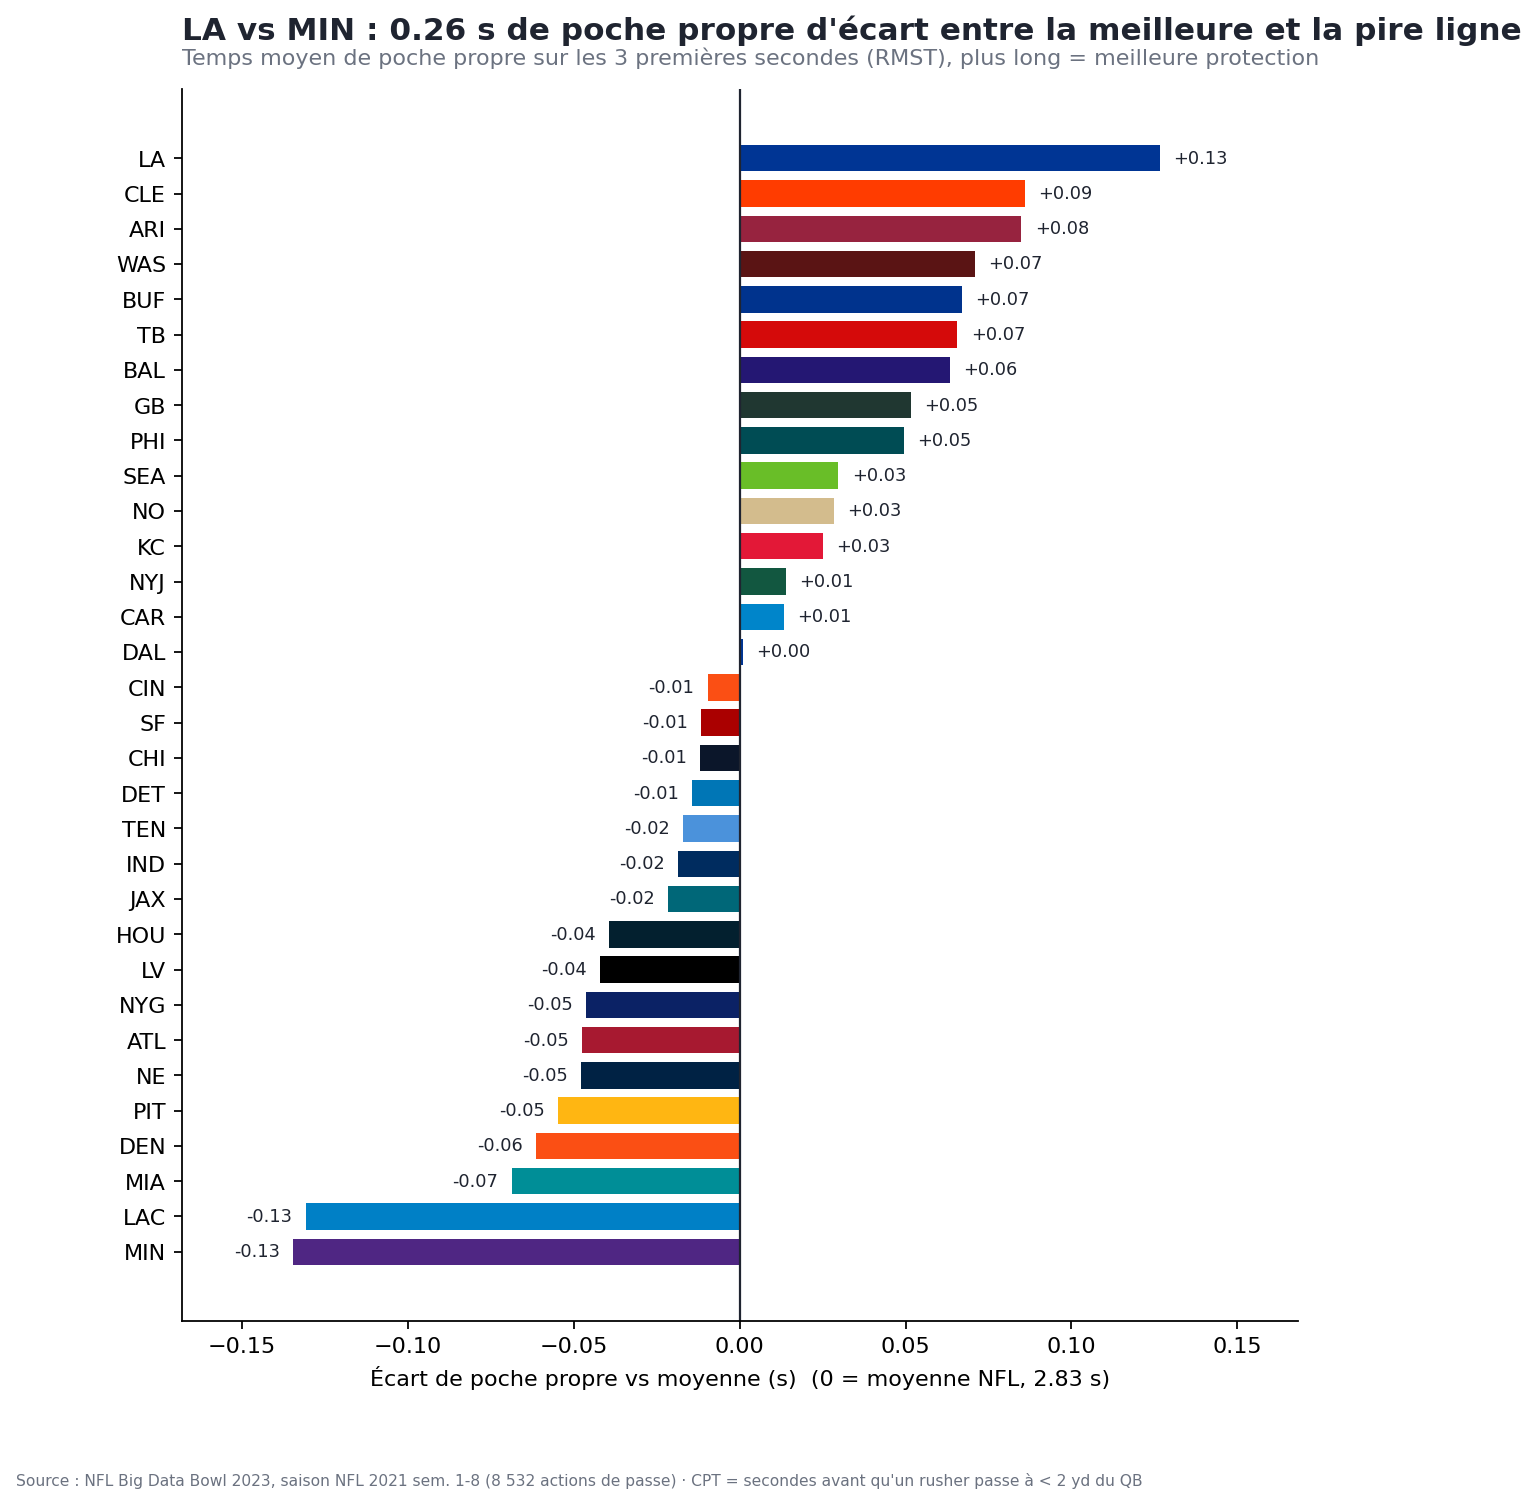

In [5]:
display(Image('outputs/01_classement_lignes_offensives.png'))

### Pass rush par équipe

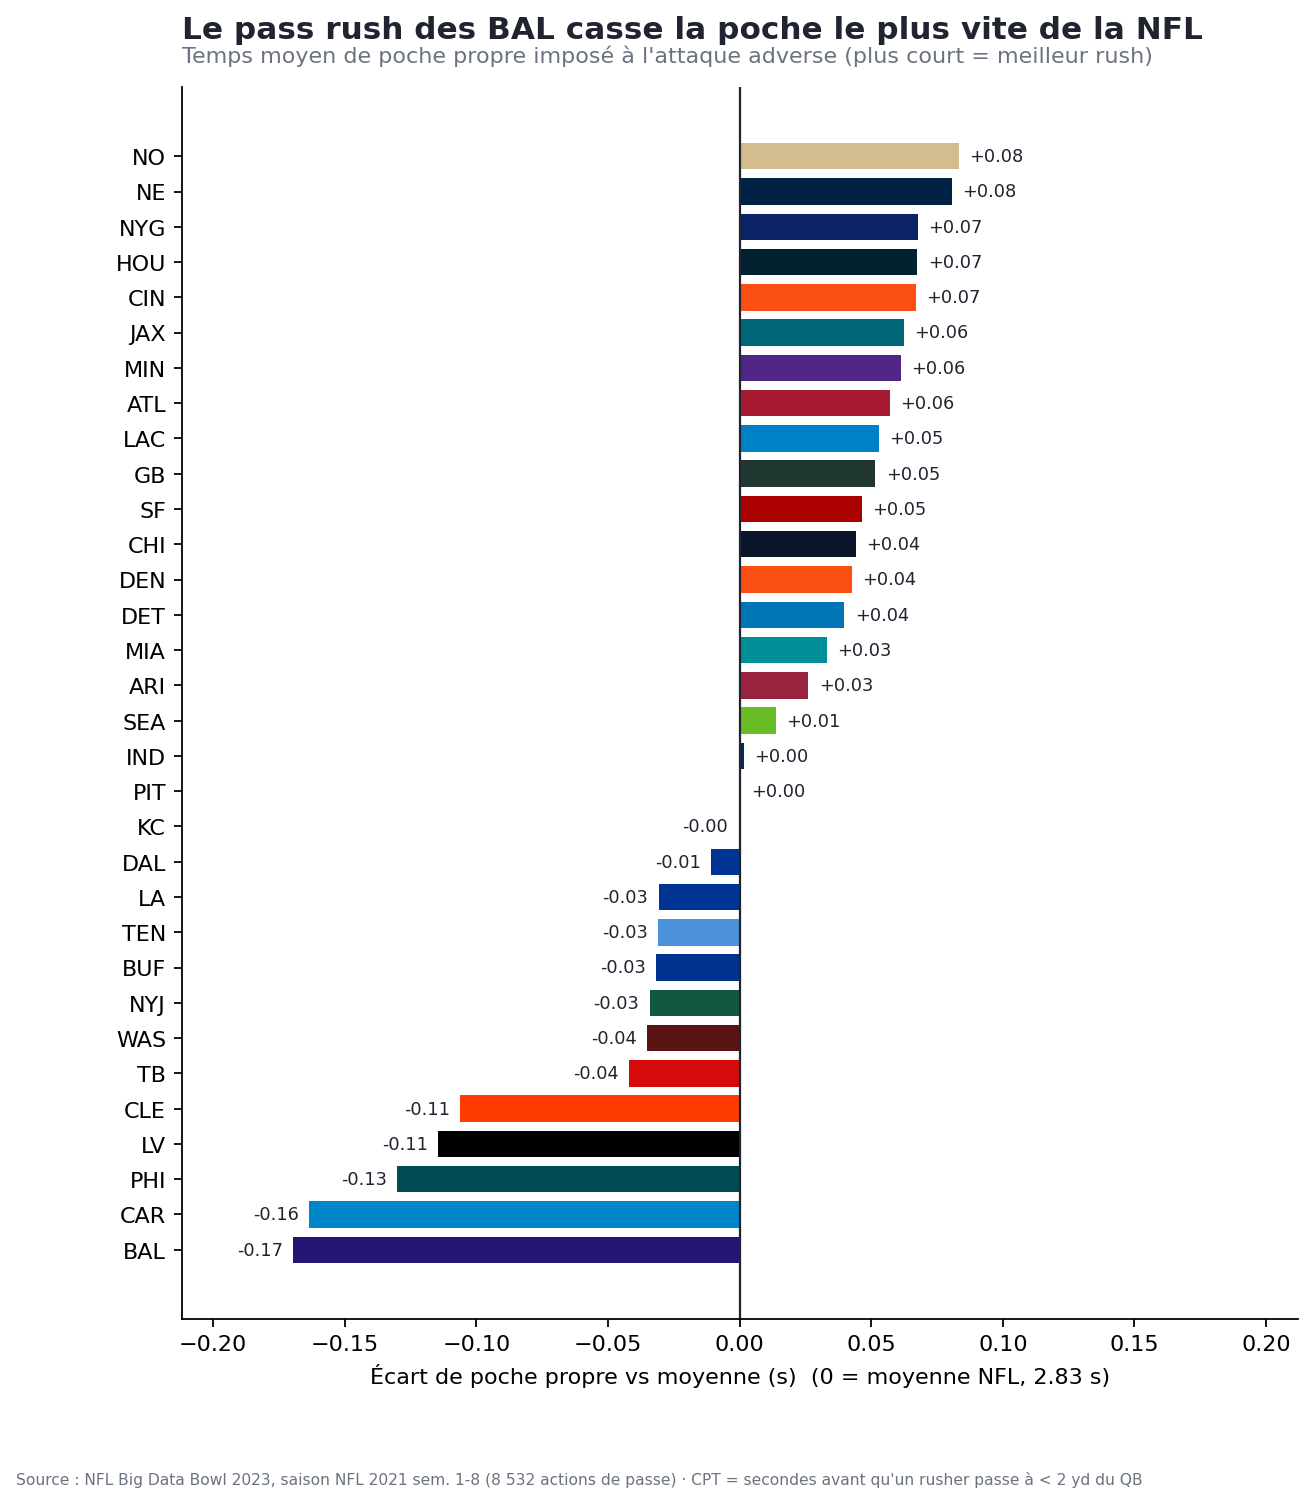

In [6]:
display(Image('outputs/02_classement_pass_rush_equipes.png'))

### Meilleurs rushers

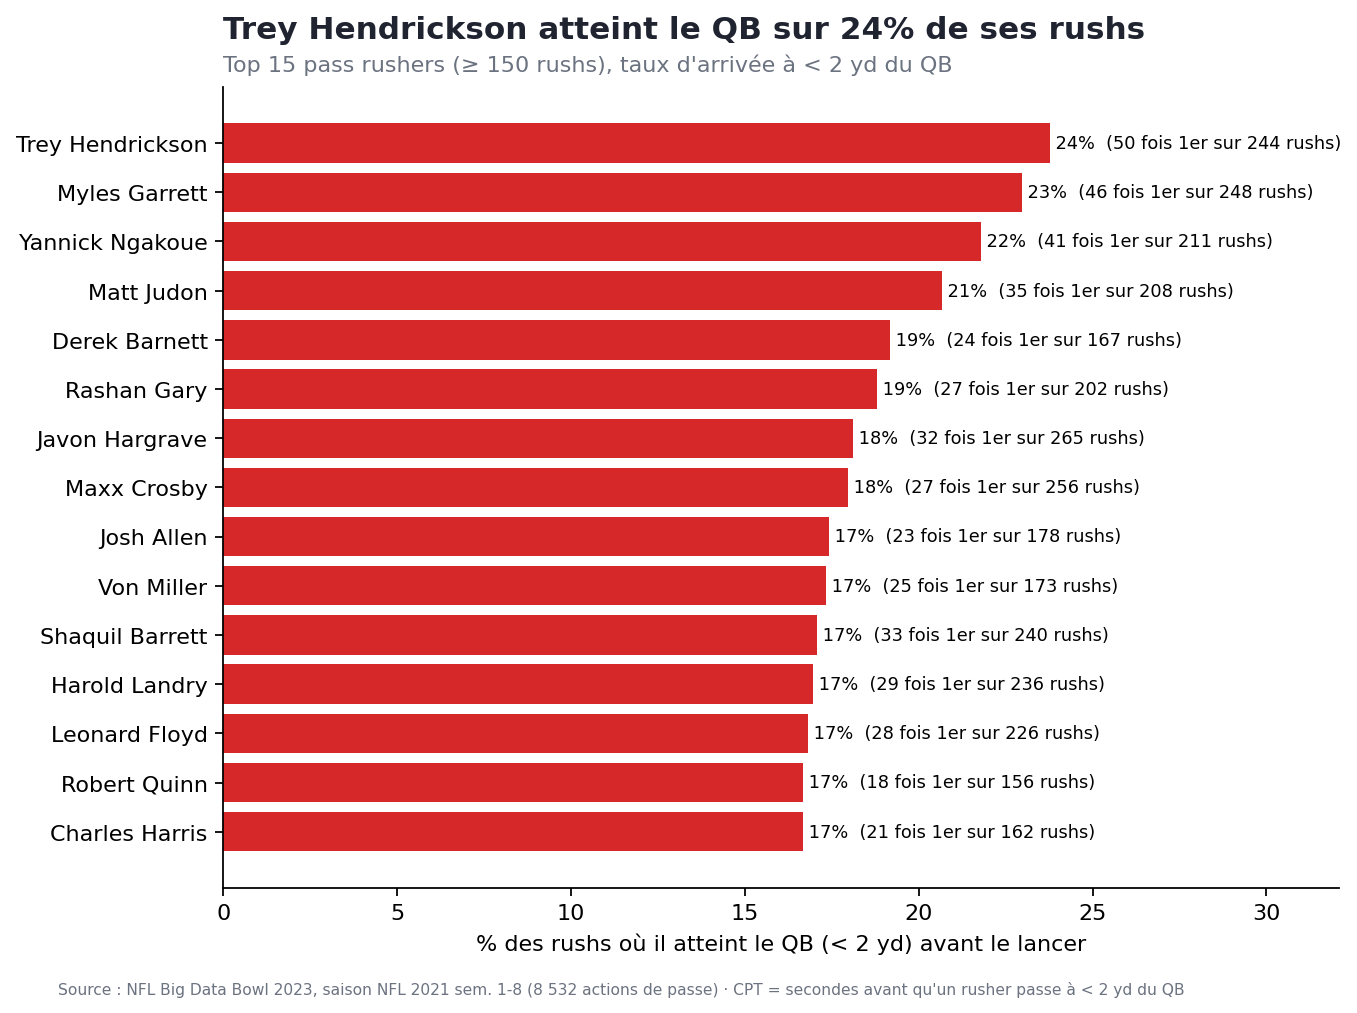

In [7]:
display(Image('outputs/03_top_pass_rushers.png'))

### Horloge de la poche

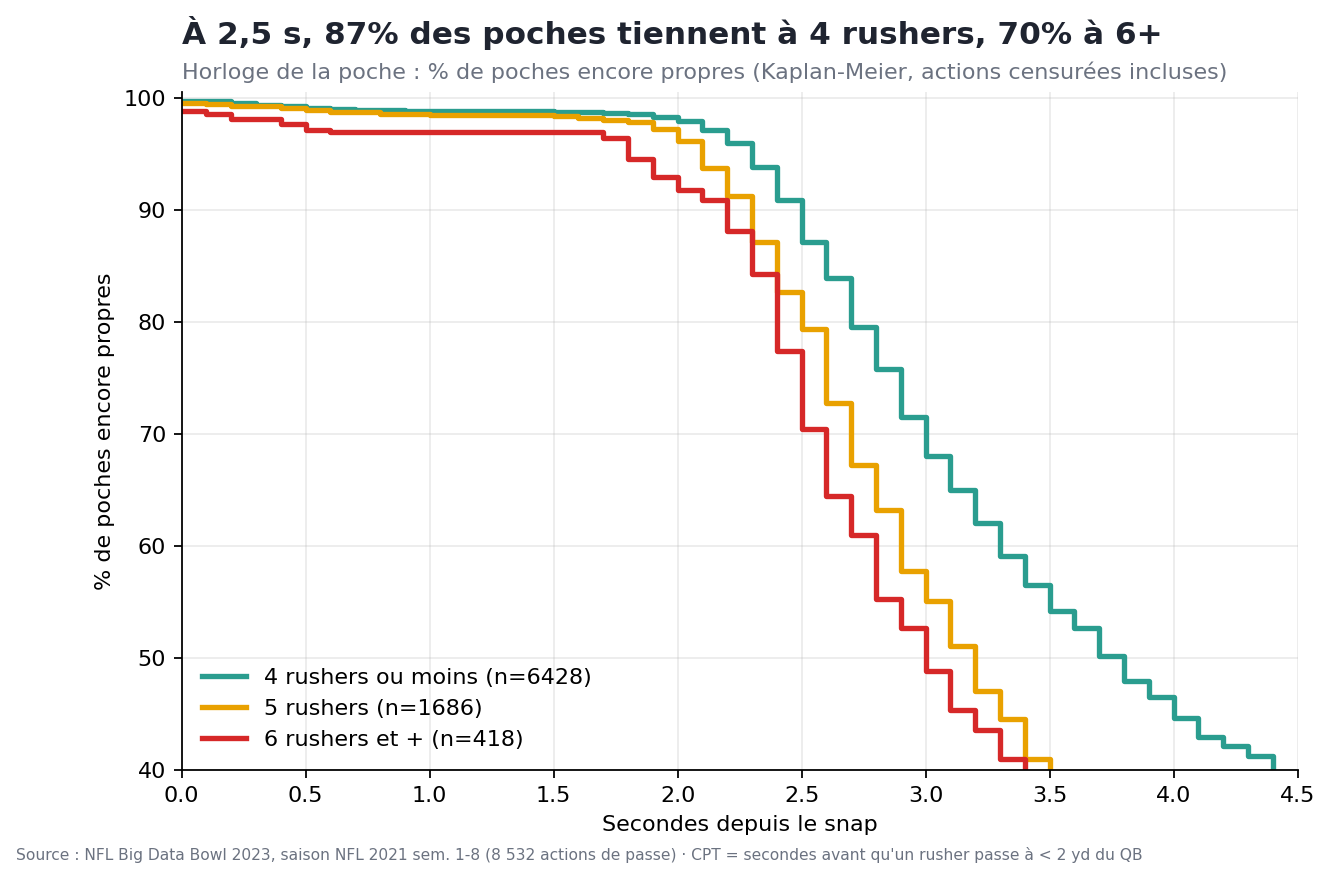

In [8]:
display(Image('outputs/04_horloge_poche_par_rushers.png'))

### CPT au-dessus de l'attendu

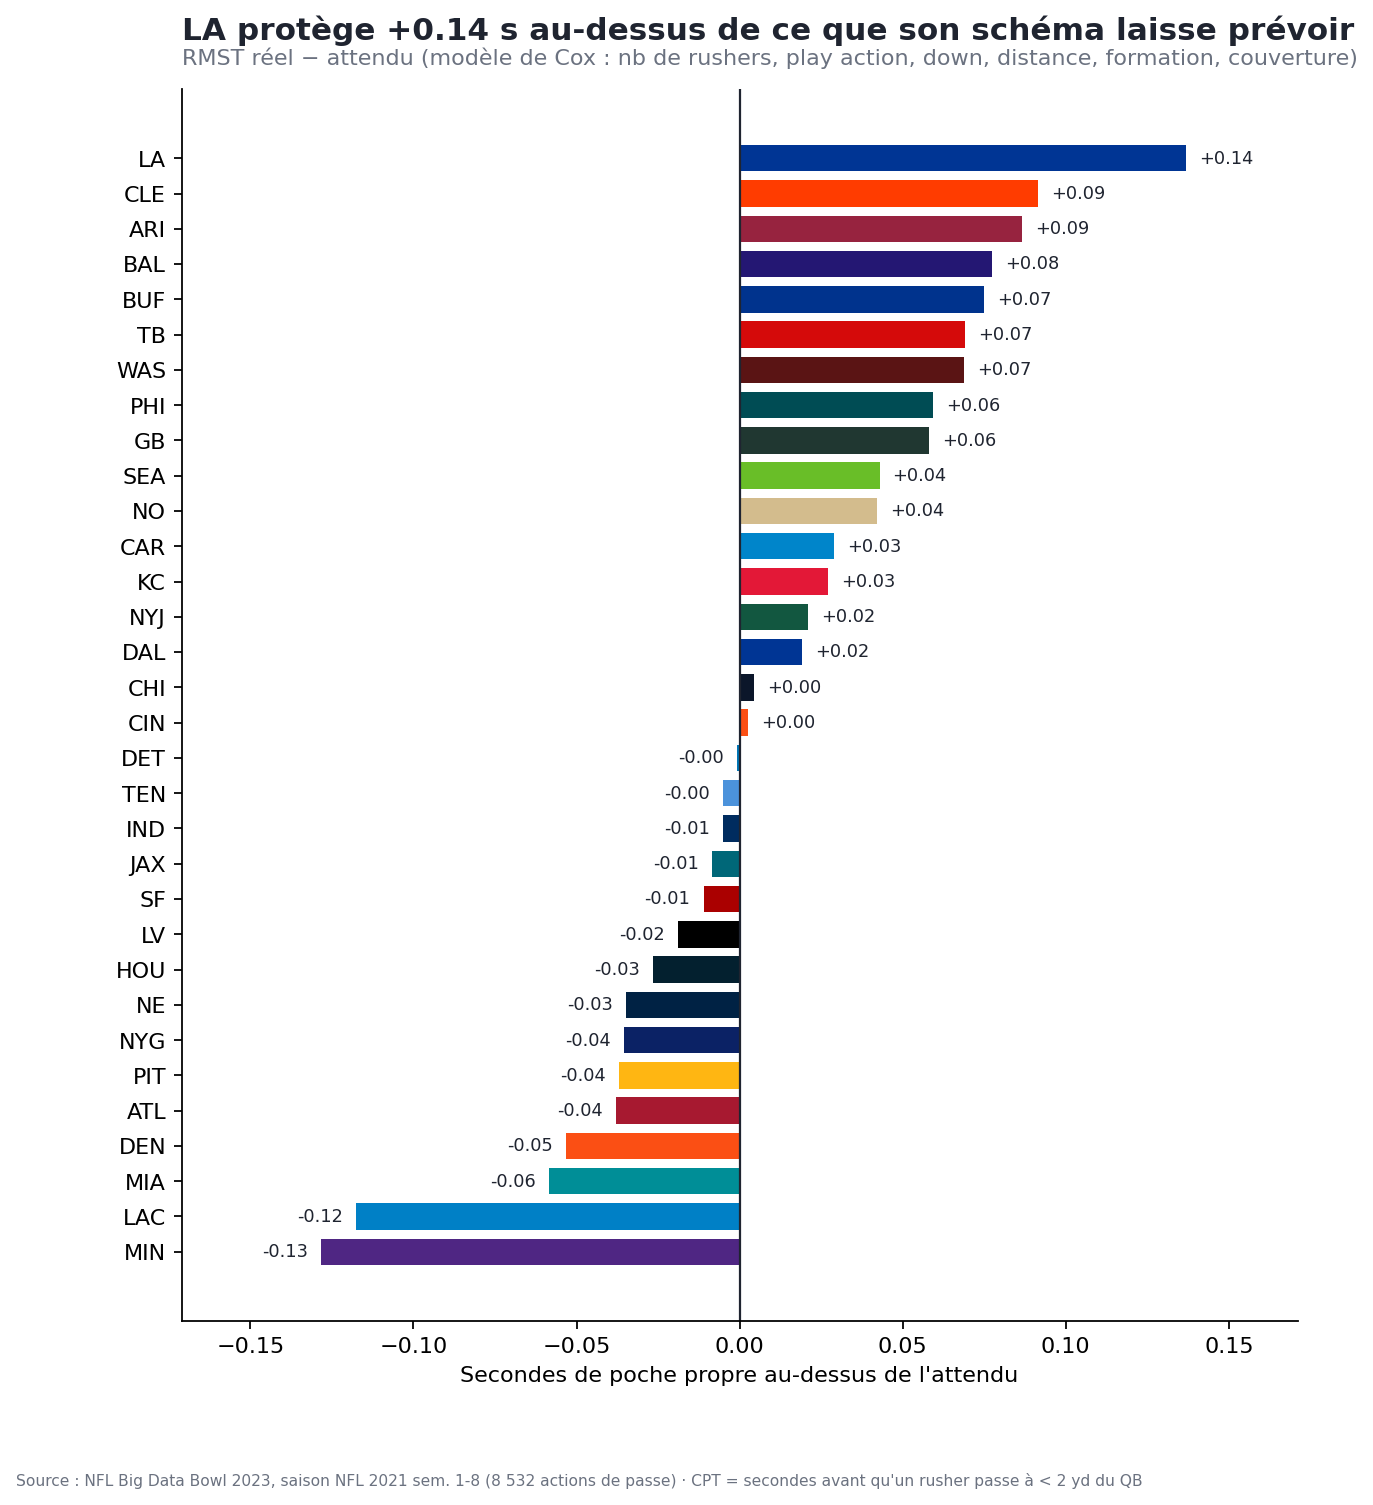

In [9]:
display(Image('outputs/06_cpt_au_dessus_attendu.png'))

### QB : horloge interne

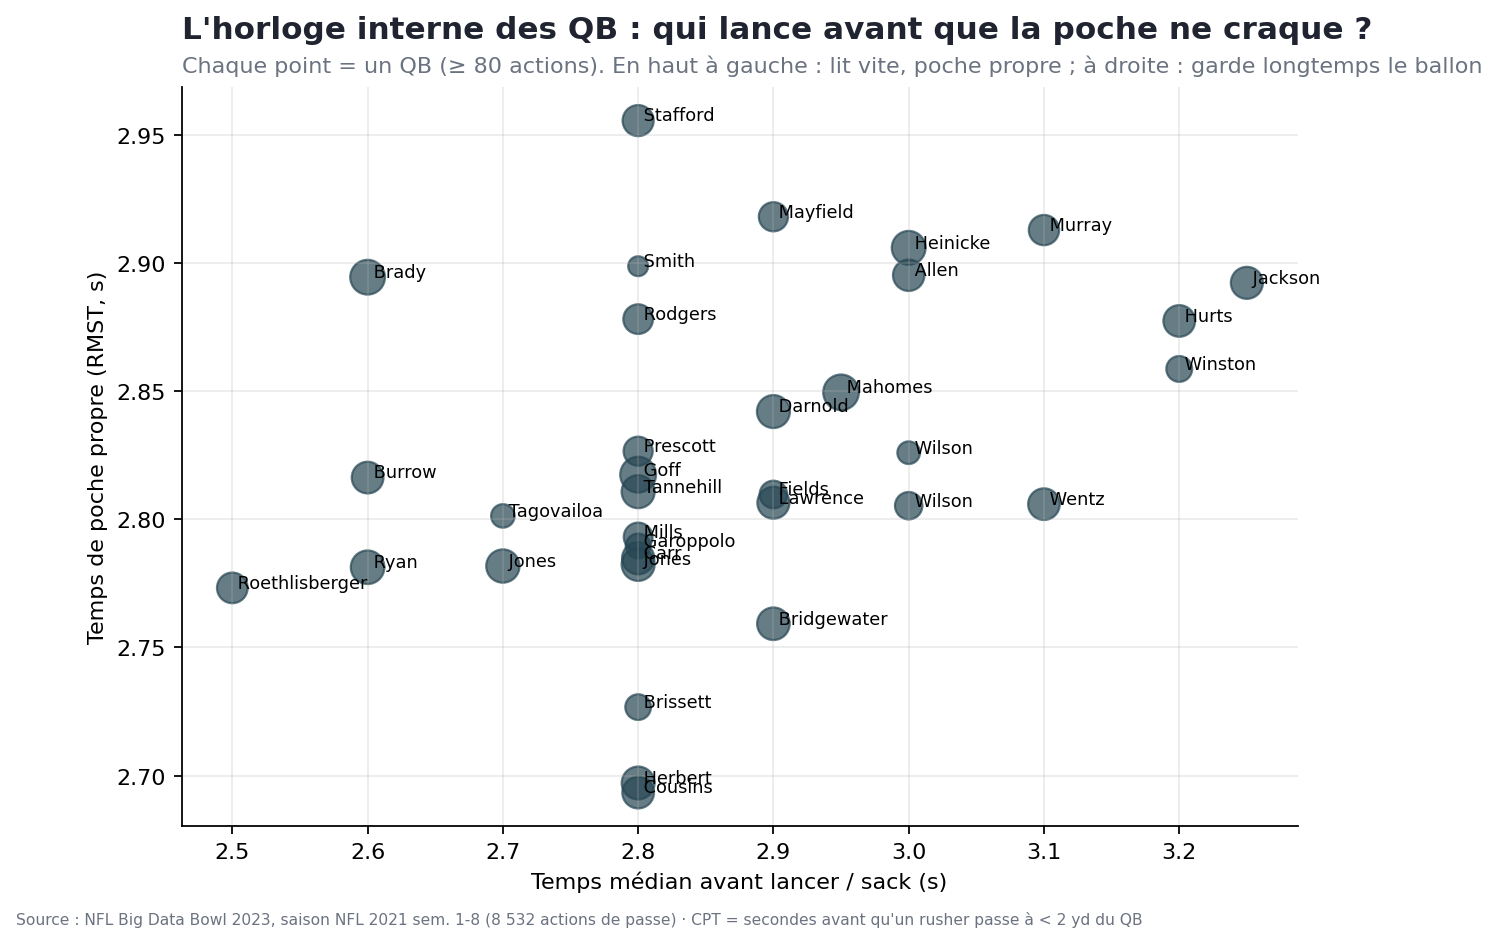

In [10]:
display(Image('outputs/07_qb_horloge_interne.png'))

### Le sack le plus rapide (GIF)

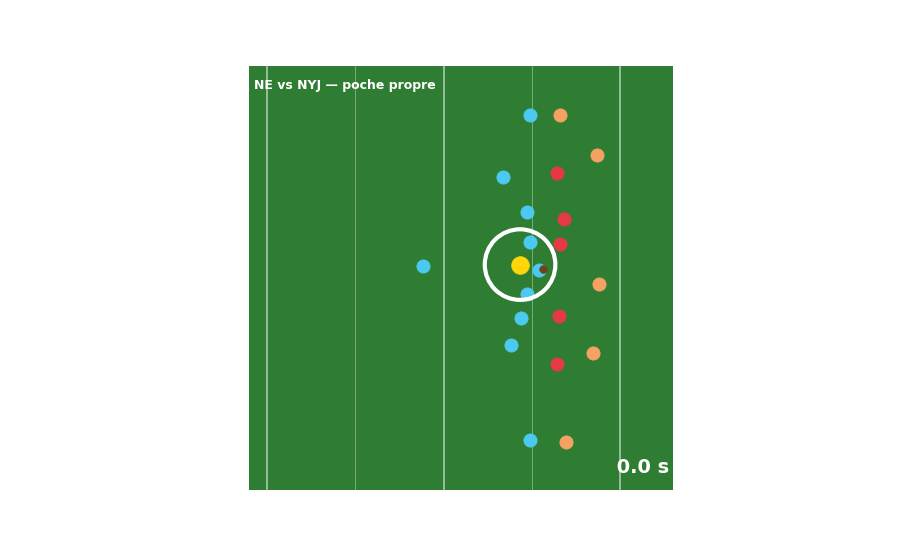

In [11]:
display(Image('outputs/08_sack_le_plus_rapide.gif'))

## 4. Robustesse du seuil (1.5 / 2 / 3 yd)

In [12]:
rob = pd.read_csv('outputs/robustesse_classement_OL.csv', index_col=0); display(rob.corr(method='spearman').round(2)); rob

,1.5 yd,2.0 yd,3.0 yd
1.5 yd,1.00,0.73,0.47
2.0 yd,0.73,1.00,0.45
3.0 yd,0.47,0.45,1.00


,1.5 yd,2.0 yd,3.0 yd
team,,,
LA,1,1,8
CLE,6,2,21
ARI,4,3,1
WAS,2,4,5
BUF,10,5,6
TB,3,6,15
BAL,8,7,2
GB,9,8,18
PHI,18,9,3


## Limites
8 semaines seulement (~250 actions/équipe), seuil de 2 yd arbitraire (classements modérément stables : ρ de Spearman ≈ 0,45-0,73 entre seuils), ~68 % des actions censurées (le QB lance avant la pression) → courbes peu fiables au-delà de ~3 s, et la distance ne capte ni les blocs ni la lecture du QB.